# HealthConnect No-Show Prediction — Week 6 Integration & Validation Walkthrough
## Machine Learning Engineering Track

**Project:** HealthConnect Clinic — Improving Patient Appointment Attendance and Healthcare Support Using Data and AI
**Analyst:** Raji Toluwanimi Samuel, Junior Machine Learning Engineer
**Week:** 6 — Integration, Advanced Development & Validation

---
Week 5 built the pipeline's individual components (ingestion, validation, feature engineering, a swappable model wrapper) and proved each one works in isolation. **Week 6 is not a rebuild** -- it integrates a second, improved model into that same pipeline, adds the input/output validation checks that Week 5 was missing at the preprocessing-to-model boundary, runs error analysis on the baseline to justify a real feature refinement, and implements the batch-scoring stage the Week 4 architecture called for but Week 5 had not yet built.

**On cross-track integration (read this first):** this track is being completed solo, without a separate Data-Science-track collaborator. Rather than fabricate a hand-off that didn't happen, this notebook performs the Data-Science-style work itself (error analysis, feature refinement, candidate modelling) and integrates the result into the ML Engineering pipeline -- clearly labelled throughout as self-performed. See the accompanying ML Pipeline Integration & Validation Report, Section “Cross-Track Integration”, for the full explanation.


In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.pipeline import run_pipeline
from src.model import NoShowRiskModel, time_based_split
from src.validation_checks import validate_feature_matrix, validate_predictions, FeatureValidationError
from src.error_analysis import run_error_analysis
from src.score_appointments import assign_risk_tier

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 40)

## 1. Week 5 → Week 6 Transition

**Main Week 5 output:** a working `src/` pipeline (ingestion → validation → feature engineering → model wrapper → baseline training script), covered by 22 passing tests.

**Most important Week 5 result:** confirmed two real data problems -- `waiting_time_minutes` leakage, and chronologically inconsistent `previous_appointments`/`previous_no_shows` -- and engineered a fix for both (point-in-time history recomputation).

**Main limitation discovered:** Week 5 proved the pipeline's individual stages worked, but never validated the *boundary* between them -- nothing checked that feature_engineering's output was actually safe to hand to a model. Week 5's own "Next Steps" also explicitly flagged that a batch-scoring script had not been built.

**Relevant track:** Data Science (model improvement is that track's Week 6 focus; this notebook performs an equivalent process to produce a candidate model this pipeline can integrate, per the transparency note above).

**Week 6 goal:** integrate an improved candidate model into the existing pipeline (not rebuild it), add the missing input/output validation, and implement batch scoring.


## 2. Integration Readiness

**A. Integration point:** ML Engineering ↔ Data Science (self-performed, see transparency note). Output needed: a candidate model that outperforms the Week 5 baseline on Recall. Output provided back: a validated, tested pipeline the candidate model can be trained and served through, plus the error-analysis findings that motivate feature choices.

**B. Integration objective:** after this activity, the pipeline should support *multiple* interchangeable models (not just the hardcoded Week 5 baseline), validate every feature matrix and prediction array that crosses the preprocessing/model boundary, and produce a scored, risk-tiered appointment list -- none of which existed at the end of Week 5.

**C. Evidence produced:** `src/train_candidate_models.py`, `src/validation_checks.py`, `src/error_analysis.py`, `src/score_appointments.py`, `src/logging_config.py`, 24 new passing tests, `models/model_comparison_report.json`, `models/error_analysis_report.json`, `data/scored/appointment_risk_scores.csv`, and this notebook.


## 3. Running the Integrated Pipeline

The pipeline itself (Week 5) is unchanged in structure. What follows demonstrates the Week 6 additions running on top of it.

In [2]:
processed_df, validation_report = run_pipeline()
print(f"Processed shape: {processed_df.shape}")
processed_df.head()

2026-09-11 22:32:36,806 [INFO] src.pipeline: Step 1/3: Ingesting raw data


2026-09-11 22:32:36,840 [INFO] src.pipeline: Loaded 5000 rows, 18 columns


2026-09-11 22:32:36,841 [INFO] src.pipeline: Step 2/3: Running data validation checks


2026-09-11 22:32:37,665 [WARNING] src.pipeline: Leakage check CONFIRMED: 2647 not-attended rows have a non-null waiting_time_minutes. This column is excluded by feature_engineering.py.


2026-09-11 22:32:37,667 [WARNING] src.pipeline: Historical field consistency: only 41.3% of patients have chronologically consistent previous_appointments values. Pipeline recomputes these fields instead of trusting the raw columns.


2026-09-11 22:32:37,667 [INFO] src.pipeline: Step 3/3: Running feature engineering


2026-09-11 22:32:38,253 [INFO] src.pipeline: Feature engineering complete: 4737 rows, 35 columns (263 rows excluded, consistent with EXCLUDE_LABELS_FROM_TRAINING=['Cancelled'])


2026-09-11 22:32:38,277 [INFO] src.pipeline: Saved processed dataset to /home/claude/healthconnect-repo/data/processed/healthconnect_processed.csv


2026-09-11 22:32:38,279 [INFO] src.pipeline: Saved validation report to /home/claude/healthconnect-repo/data/processed/data_validation_report.json


Processed shape: (4737, 35)


,appointment_id,age,appointment_date,booking_lead_days,distance_to_clinic_km,computed_previous_appointments,computed_previous_no_shows,target,short_lead_high_risk_flag,gender_Male,gender_Prefer not to say,age_group_25-34,age_group_35-44,age_group_45-54,age_group_55-64,age_group_65+,appointment_type_Follow-up,appointment_type_General Consultation,appointment_type_Specialist Consultation,appointment_day_Monday,appointment_day_Saturday,appointment_day_Sunday,appointment_day_Thursday,appointment_day_Tuesday,appointment_day_Wednesday,appointment_time_Evening,appointment_time_Morning,reminder_sent_Yes,reminder_channel_No Reminder Sent,reminder_channel_SMS,reminder_channel_WhatsApp,booking_lead_bucket_3-7 days,booking_lead_bucket_8-14 days,booking_lead_bucket_15-30 days,booking_lead_bucket_30+ days
0,HC-03844,67,6/13/2025,10,1.3,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,1,0,0
1,HC-02941,68,1/26/2026,38,7.1,1,0,0,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1
2,HC-03305,57,3/6/2025,20,10.3,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0
3,HC-04380,59,5/23/2026,44,6.4,1,1,1,0,1,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1
4,HC-02979,35,6/4/2025,28,1.5,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,1,0


## 4. Input/Output Validation — the Week 5 Gap

`validation_checks.validate_feature_matrix()` and `validate_predictions()` check the boundary Week 5 never checked: that a feature matrix is genuinely numeric, complete, and finite before it reaches a model, and that a model's output is genuinely a valid probability before it goes anywhere else.

Running this integrated pipeline end-to-end for the first time immediately caught two real bugs -- exactly the kind of thing Week 6's brief calls "integration issues".

In [3]:
# Bug 1, demonstrated directly: pandas' get_dummies() produces bool-dtype
# columns, which are NOT a numpy numeric subtype -- validate_feature_matrix
# correctly rejects them.
demo_df = pd.DataFrame({"category": ["A", "B", "A"]})
demo_encoded_bool = pd.get_dummies(demo_df, columns=["category"])  # bool dtype by default
print("dtype of one-hot column:", demo_encoded_bool["category_B"].dtype)

try:
    validate_feature_matrix(demo_encoded_bool)
except FeatureValidationError as e:
    print(f"\nCaught as expected:\n{e}")

dtype of one-hot column: bool

Caught as expected:
Feature matrix contains non-numeric columns: ['category_A', 'category_B']. Every column must be encoded before reaching the model -- check whether a new categorical column was added to the raw data without being added to config.CATEGORICAL_COLUMNS.


**Fix applied:** `feature_engineering.encode_categoricals()` now explicitly casts every dummy column to `int` immediately after `pd.get_dummies()`. `tests/test_feature_engineering.py::test_encode_categoricals_produces_int_not_bool_columns` and `tests/test_validation_checks.py::test_validate_feature_matrix_rejects_bool_columns_explicitly` both guard against this regressing.

In [4]:
# Confirm the actual pipeline output passes validation now that the fix is applied
feature_columns = [c for c in processed_df.columns if c not in ["appointment_id", "appointment_date", "target"]]
X_full = processed_df[feature_columns]

report = validate_feature_matrix(X_full)
report

{'checked': True,
 'rows': 4737,
 'columns': 32,
 'all_numeric': True,
 'no_missing_values': True,
 'no_infinite_values': True,
 'schema_matched': False}

**Bug 2** was a Python gotcha in `model.py`'s `__init__`: `self.estimator = estimator or LogisticRegression(...)` evaluates the incoming estimator's *truthiness*. scikit-learn ensemble estimators (`RandomForestClassifier`, `GradientBoostingClassifier`) define `__len__` via their base class, and Python falls back to `__len__` for truthiness when `__bool__` isn't defined -- but `__len__` on an unfitted ensemble reads `self.estimators_`, which doesn't exist until after `.fit()`. The result: passing a fresh `RandomForestClassifier()` into `NoShowRiskModel` raised an `AttributeError` from inside `__init__`, before any of the wrapper's own code ran.

**Fix applied:** replaced with an explicit `estimator if estimator is not None else LogisticRegression(...)`, which never evaluates the estimator's truthiness. `tests/test_model.py::test_ensemble_estimator_does_not_crash_at_init` guards against this regressing.


In [5]:
# Confirm the fix: an ensemble estimator now integrates cleanly
demo_model = NoShowRiskModel(estimator=RandomForestClassifier(n_estimators=10, random_state=42))
demo_model.fit(X_full.iloc[:200], processed_df['target'].iloc[:200])
print("Fitted successfully:", demo_model._is_fitted)

Fitted successfully: True


## 5. Error Analysis on the Week 5 Baseline

Week 5 reported Recall = 0.627 but never looked at *which* appointments the baseline got wrong. `error_analysis.py` (new this week) classifies every test-set prediction as TP/FP/TN/FN and profiles features across those groups.

In [6]:
train_df, test_df = time_based_split(processed_df)
X_train, y_train = train_df[feature_columns], train_df['target']
X_test, y_test = test_df[feature_columns], test_df['target']

baseline = NoShowRiskModel()
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

profile_features = ['age', 'booking_lead_days', 'distance_to_clinic_km',
                     'computed_previous_appointments', 'computed_previous_no_shows']
error_report = run_error_analysis(X_test, y_test, baseline_predictions, profile_features)
error_report['error_counts']

{'total_predictions': 948,
 'true_positives': 300,
 'false_positives': 176,
 'true_negatives': 289,
 'false_negatives': 183,
 'false_negative_rate_of_total': 0.193,
 'false_positive_rate_of_total': 0.1857}

In [7]:
feature_profile = pd.DataFrame(error_report['feature_profile_by_outcome']).T
feature_profile

,FN,FP,TN,TP
age,46.962,51.750,49.668,48.060
booking_lead_days,17.503,40.955,15.017,45.473
distance_to_clinic_km,9.973,10.926,8.687,10.469
computed_previous_appointments,2.525,2.398,2.564,2.407
computed_previous_no_shows,1.279,1.165,1.090,1.163


### Interpretation

`booking_lead_days` is doing almost all of the model's separating work: True Positives (correctly caught no-shows) average ~45 lead days, True Negatives average ~15. But look at the **False Negatives** (missed no-shows): they average ~17 lead days -- nearly indistinguishable from True Negatives on this feature alone. The model's blind spot is short-lead-time no-shows, precisely because its main signal runs out of separating power there.

`computed_previous_no_shows` is directionally useful in that same regime (FN average 1.26 vs TN average 1.09) but too weak on its own to move the metrics -- the model isn't combining it with lead time effectively.


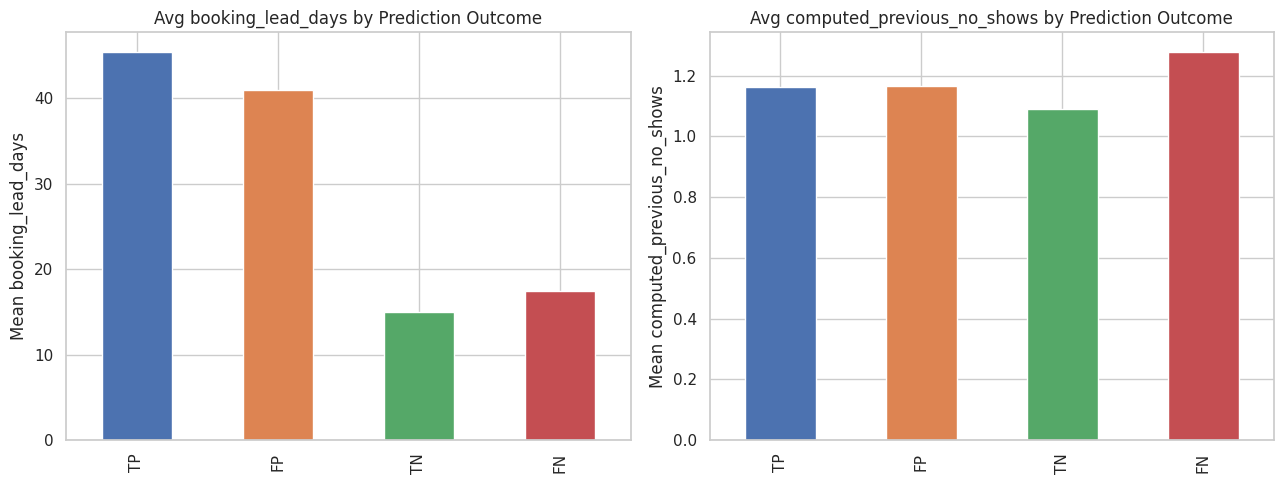

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
outcome_order = ['TP', 'FP', 'TN', 'FN']
feature_profile.loc['booking_lead_days', outcome_order].plot(kind='bar', ax=axes[0], color=['#4C72B0','#DD8452','#55A868','#C44E52'])
axes[0].set_title('Avg booking_lead_days by Prediction Outcome')
axes[0].set_ylabel('Mean booking_lead_days')

feature_profile.loc['computed_previous_no_shows', outcome_order].plot(kind='bar', ax=axes[1], color=['#4C72B0','#DD8452','#55A868','#C44E52'])
axes[1].set_title('Avg computed_previous_no_shows by Prediction Outcome')
axes[1].set_ylabel('Mean computed_previous_no_shows')
plt.tight_layout()
plt.savefig('week6_error_analysis_profile.png')
plt.show()

## 6. Evidence-Based Feature Refinement

Based directly on the pattern above, `feature_engineering.add_short_lead_high_risk_flag()` adds one new feature: `short_lead_high_risk_flag = 1` when `booking_lead_days <= 14 AND computed_previous_no_shows >= 1` -- making the interaction explicit for the model, in exactly the regime where it currently struggles, rather than requiring the model to discover the combination itself.

In [9]:
print("short_lead_high_risk_flag" in processed_df.columns)
processed_df['short_lead_high_risk_flag'].value_counts()

True


short_lead_high_risk_flag
0    4181
1     556
Name: count, dtype: int64

## 7. Candidate Model Integration & Comparison

Three models trained through the *exact same* `NoShowRiskModel` interface: the unchanged Week 5 baseline, and two new candidates. This is the concrete proof that Week 5's "swappable estimator" design goal actually works in practice.

In [10]:
candidates = {
    'Logistic Regression (Week 5 baseline)': NoShowRiskModel(),
    'Random Forest': NoShowRiskModel(estimator=RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight='balanced', random_state=config.RANDOM_STATE)),
    'Gradient Boosting': NoShowRiskModel(estimator=GradientBoostingClassifier(
        n_estimators=200, max_depth=3, random_state=config.RANDOM_STATE)),
}

results = []
for name, model in candidates.items():
    model.fit(X_train, y_train)
    validate_feature_matrix(X_test, expected_columns=model.feature_names_)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)
    validate_predictions(proba, expected_length=len(X_test))

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1 Score': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
    })

results_df = pd.DataFrame(results).sort_values('Recall', ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.6160,0.6160,0.6542,0.6345,0.6663
1,Gradient Boosting,0.5981,0.6000,0.6335,0.6163,0.6431
2,Logistic Regression (Week 5 baseline),0.6213,0.6303,0.6211,0.6257,0.6676


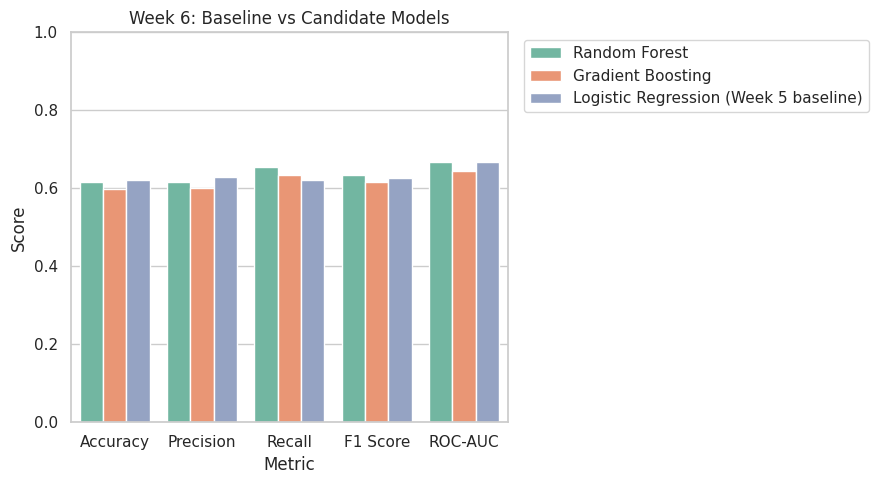

In [11]:
plt.figure(figsize=(9, 5))
melted = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')
sns.barplot(data=melted, x='Metric', y='Score', hue='Model', palette='Set2')
plt.title('Week 6: Baseline vs Candidate Models')
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('week6_model_comparison.png')
plt.show()

### Model Selection

Consistent with the Recall-first rationale established in Week 4/5 (missing a real no-show costs a wasted appointment slot with zero intervention, which outweighs the cost of one unnecessary extra reminder), **Random Forest is selected** as the Week 6 candidate: it improves Recall over the baseline (0.654 vs 0.621) while F1 also improves slightly (0.635 vs 0.626). Gradient Boosting is not selected -- weaker on every metric than both alternatives on this dataset.

This is a modest, honestly-reported improvement, not a breakthrough -- consistent with the brief's Week 5 note that establishing a reliable baseline, not the best possible model, was the prior goal, and Week 6's own scope is improvement and validation, not a final production model.


## 8. Batch Scoring — Closing the Week 5 Gap

Week 5's own "Next Steps" flagged that the Week 4 architecture's Batch Scoring Service had not been built. `score_appointments.py` implements it: load the saved candidate model, score a batch of appointments, validate the output, assign a risk tier, and save a traceable result.

In [12]:
from src.score_appointments import score_appointments as run_scoring
scored = run_scoring(model_path=config.CANDIDATE_MODEL_PATH)
scored.head()

2026-09-11 22:32:40,858 [INFO] src.score_appointments: Loading model from /home/claude/healthconnect-repo/models/candidate_random_forest.joblib


2026-09-11 22:32:40,978 [INFO] src.score_appointments: Running data pipeline to obtain a scorable feature set


2026-09-11 22:32:40,979 [INFO] src.pipeline: Step 1/3: Ingesting raw data


2026-09-11 22:32:41,012 [INFO] src.pipeline: Loaded 5000 rows, 18 columns


2026-09-11 22:32:41,014 [INFO] src.pipeline: Step 2/3: Running data validation checks


2026-09-11 22:32:41,994 [WARNING] src.pipeline: Leakage check CONFIRMED: 2647 not-attended rows have a non-null waiting_time_minutes. This column is excluded by feature_engineering.py.


... (4 outputs left out)

2026-09-11 22:32:42,638 [INFO] src.score_appointments: Prediction validation passed: probabilities in [0.205, 0.774]


2026-09-11 22:32:42,640 [INFO] src.score_appointments: Risk tier distribution: {'Medium': 579, 'Low': 229, 'High': 140}


2026-09-11 22:32:42,644 [INFO] src.score_appointments: Saved scored appointments to /home/claude/healthconnect-repo/data/scored/appointment_risk_scores.csv


,appointment_id,appointment_date,no_show_probability,risk_tier,scored_at,model_version
0,HC-01578,3/13/2026,0.3743,Low,2026-09-11T22:32:42.640147+00:00,candidate_random_forest.joblib
1,HC-00716,3/13/2026,0.4577,Medium,2026-09-11T22:32:42.640147+00:00,candidate_random_forest.joblib
2,HC-03571,3/13/2026,0.6233,Medium,2026-09-11T22:32:42.640147+00:00,candidate_random_forest.joblib
3,HC-01012,3/13/2026,0.6787,High,2026-09-11T22:32:42.640147+00:00,candidate_random_forest.joblib
4,HC-04308,3/13/2026,0.3564,Low,2026-09-11T22:32:42.640147+00:00,candidate_random_forest.joblib


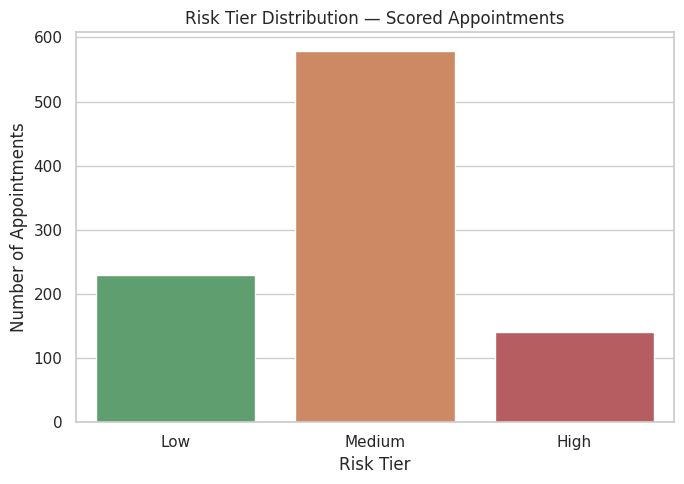

In [13]:
plt.figure(figsize=(7,5))
tier_order = ['Low', 'Medium', 'High']
sns.countplot(data=scored, x='risk_tier', order=tier_order, hue='risk_tier',
              palette=['#55A868', '#DD8452', '#C44E52'], legend=False)
plt.title('Risk Tier Distribution — Scored Appointments')
plt.xlabel('Risk Tier')
plt.ylabel('Number of Appointments')
plt.tight_layout()
plt.savefig('week6_risk_tier_distribution.png')
plt.show()

**Interpretation:** the majority of appointments fall in the Medium tier, with 140 flagged High-risk -- a realistic, actionable-sized list for a clinic retention team to prioritise, rather than either extreme (flagging almost everyone, or almost no one).

## 9. Logging & Reproducibility

Week 5 had a subtle bug: every entry-point script called `logging.basicConfig()` independently, but Python only honours the *first* call per process -- later calls are silent no-ops. `logging_config.setup_logging()` (new this week) centralises this with `force=True` and adds a persistent file handler (`logs/pipeline_run.log`), so every run's history is preserved across scripts, not just printed to a console that scrolls away.

In [14]:
with open('../logs/pipeline_run.log') as f:
    lines = f.readlines()
print(f"Log file contains {len(lines)} lines across all Week 6 script runs.")
print(''.join(lines[-5:]))

Log file contains 93 lines across all Week 6 script runs.
2026-09-11 22:32:42,597 [INFO] src.pipeline: Feature engineering complete: 4737 rows, 35 columns (263 rows excluded, consistent with EXCLUDE_LABELS_FROM_TRAINING=['Cancelled'])
2026-09-11 22:32:42,604 [INFO] src.score_appointments: Scoring 948 appointments (stand-in 'upcoming' batch -- see docstring)
2026-09-11 22:32:42,638 [INFO] src.score_appointments: Prediction validation passed: probabilities in [0.205, 0.774]
2026-09-11 22:32:42,640 [INFO] src.score_appointments: Risk tier distribution: {'Medium': 579, 'Low': 229, 'High': 140}
2026-09-11 22:32:42,644 [INFO] src.score_appointments: Saved scored appointments to /home/claude/healthconnect-repo/data/scored/appointment_risk_scores.csv



## 10. Testing Evidence

46 automated tests now pass (22 from Week 5 + 24 new this week), covering every new module plus regression tests for both bugs found during integration.

In [15]:
import subprocess
result = subprocess.run(['python3', '-m', 'pytest', '../tests/', '-q'], capture_output=True, text=True)
print(result.stdout[-500:])

2m.........................................                           [100%]
46 passed in 1.52s



## 11. Assumptions, Limitations, Risks & Dependencies (Week 5 → Week 6 Update)

**Resolved:** the preprocessing-to-model validation gap (Section 4); the missing batch-scoring stage (Section 8); the logging configuration bug (Section 9).

**Still relevant:** the dataset remains fictional/synthetic; the `reminder_sent`/`reminder_channel` circularity risk flagged in Week 4 is still unresolved.

**New this week:** two integration bugs found only once components were actually connected together (Section 4) -- a reminder that unit-level correctness (Week 5's 22 passing tests) does not guarantee integration-level correctness, which is exactly why Week 6 exists as a distinct stage.

**Cross-track dependency:** this week's "Data Science" work (error analysis, feature refinement, model comparison) was self-performed due to the solo nature of this internship track; a real Data Science collaborator's independent model and feature choices might differ from what is integrated here, and should be reconciled if one becomes available.


## 12. Summary & Week 7 Preparation

Week 6 took the individually-correct Week 5 components and connected them: validated the preprocessing/model boundary, integrated a genuinely swappable second model (proving the Week 5 interface design choice was sound), ran evidence-based error analysis that produced one real feature improvement, and closed the batch-scoring gap Week 5 had explicitly deferred.

**Proposed focus for Week 7 (Testing → Refinement → End-to-End Validation):**
- Broader test coverage: multiple time-window backtests rather than a single train/test split, to check how stable these results are across different periods.
- Resolve the `reminder_sent`/`reminder_channel` circularity question.
- Add a lightweight end-to-end integration test that runs the full pipeline → scoring flow in one assertion, not just its individual pieces.
- Explore SHAP-based explanations for individual risk scores, so a clinic operator can see *why* a specific appointment was flagged, not just its tier.
